In [1]:
from pathlib import Path

import cmocean as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

import pinner2026_jpo_code
import pinner2026_jpo_code.spectra

RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [2]:
u = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv", parse_dates=True, index_col=0)
u.columns = u.columns.astype(float)
v = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv", parse_dates=True, index_col=0)
v.columns = v.columns.astype(float)

In [3]:
u.columns

Index([ 30.23,  38.23,  46.23,  54.23,  62.23,  70.23,  78.23,  86.23,  94.23,
       102.23, 110.23, 118.23, 126.23, 134.23, 142.23, 150.23, 158.23, 166.23,
       174.23, 182.23, 190.23],
      dtype='float64')

# Velocity and Phase Differences

In [4]:
lower_u = (
    u[[46.23, 54.23, 62.23]].mean(axis="columns").iloc[30:].interpolate(method="time", limit=3)
)
lower_v = (
    v[[46.23, 54.23, 62.23]].mean(axis="columns").iloc[30:].interpolate(method="time", limit=3)
)
upper_u = (
    u[[142.23, 150.23, 158.23]].mean(axis="columns").iloc[30:].interpolate(method="time", limit=3)
)
upper_v = (
    v[[142.23, 150.23, 158.23]].mean(axis="columns").iloc[30:].interpolate(method="time", limit=3)
)

In [5]:
# filter to f--N frequencies
fs = 1 / (1 * 60 * 60)  # sampling period of 1 hour
cut = 1 / (13.8 * 60 * 60)  # tail end of the continuum
# cut = 1 / (7 * 60 * 60)  # tail end of the continuum
order = 40

sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")

# use filtfilt with 2 filtering passes to prevent an artificial phase shift
lower_u_fN = pd.Series(index=lower_u.index, data=signal.sosfiltfilt(sos, lower_u.to_numpy()))
upper_u_fN = pd.Series(index=upper_u.index, data=signal.sosfiltfilt(sos, upper_u.to_numpy()))
lower_v_fN = pd.Series(index=lower_v.index, data=signal.sosfiltfilt(sos, lower_v.to_numpy()))
upper_v_fN = pd.Series(index=upper_v.index, data=signal.sosfiltfilt(sos, upper_v.to_numpy()))

<Axes: >

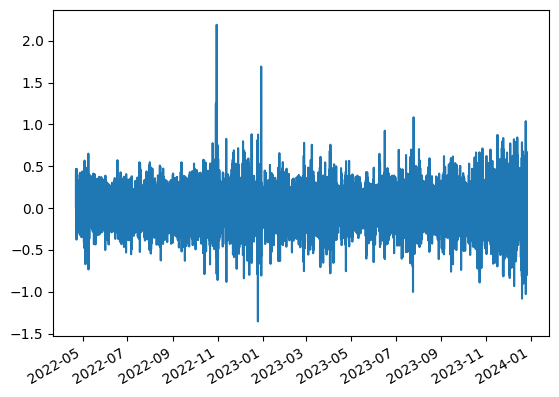

In [6]:
(lower_v_fN - upper_v_fN).plot()

(0.01, 0.15)

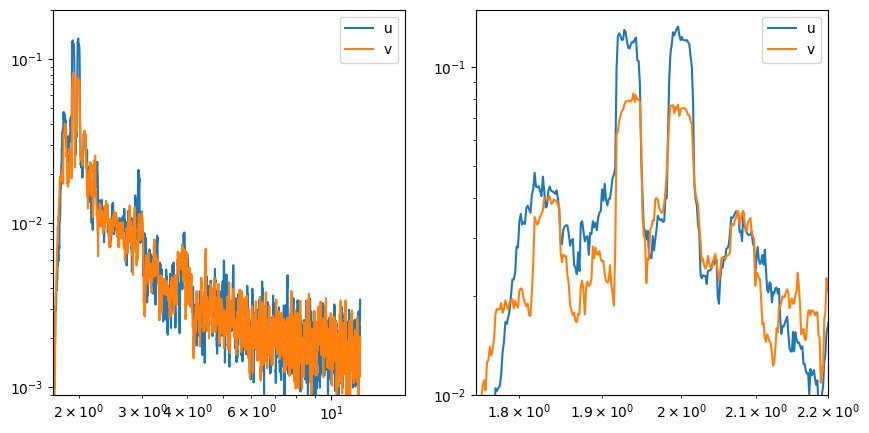

In [7]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    (lower_u_fN - upper_u_fN).to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    (lower_v_fN - upper_v_fN).to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
ax[0].set_xlim(1.7, 16)
ax[0].set_ylim(9e-4, 0.2)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.75, 2.2)
ax[1].set_ylim(1e-2, 0.15)

# Filter to just inertial frequencies

In [8]:
def filter_to_f(col):
    fs = 1 / (1 * 60 * 60)
    low_cut = 1 / (13.8 * 60 * 60)
    high_cut = 1 / (12.5 * 60 * 60)
    order = 40
    sos = signal.butter(N=order, Wn=(low_cut, high_cut), btype="bandpass", fs=fs, output="sos")
    filtered = signal.sosfiltfilt(sos, col.to_numpy())
    return pd.Series(filtered, index=col.index)


u_f = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_f, axis="index")
v_f = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_f, axis="index")

(0.01, 0.07)

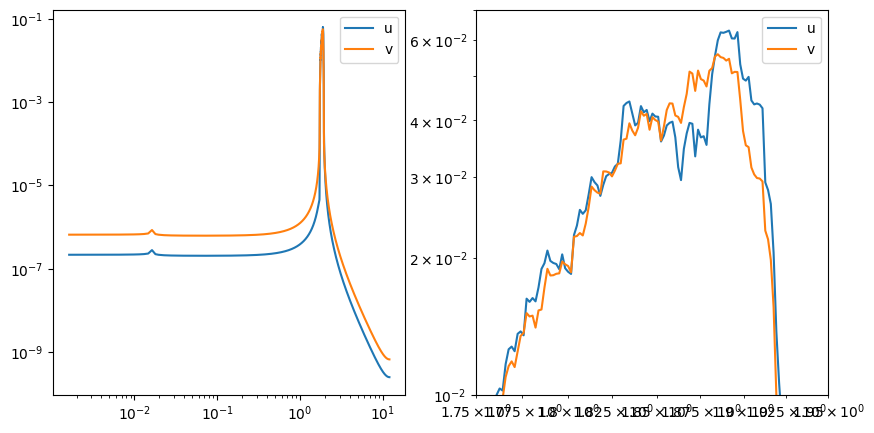

In [9]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10

mab = 54.23
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_f.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    v_f.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
# ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(9e-4, 0.2)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.75, 1.95)
ax[1].set_ylim(1e-2, 7e-2)

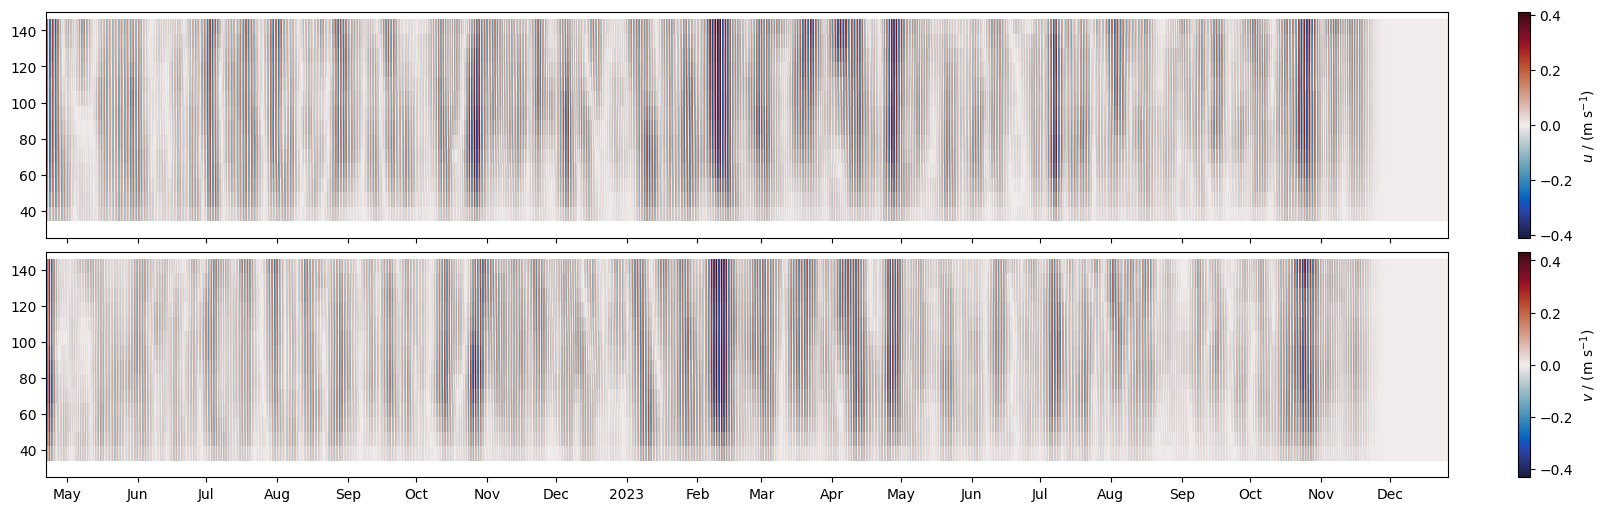

In [10]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, figsize=(16, 5), layout="constrained")

MAX_REASONABLE_VELOCITY = 4
max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=32)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

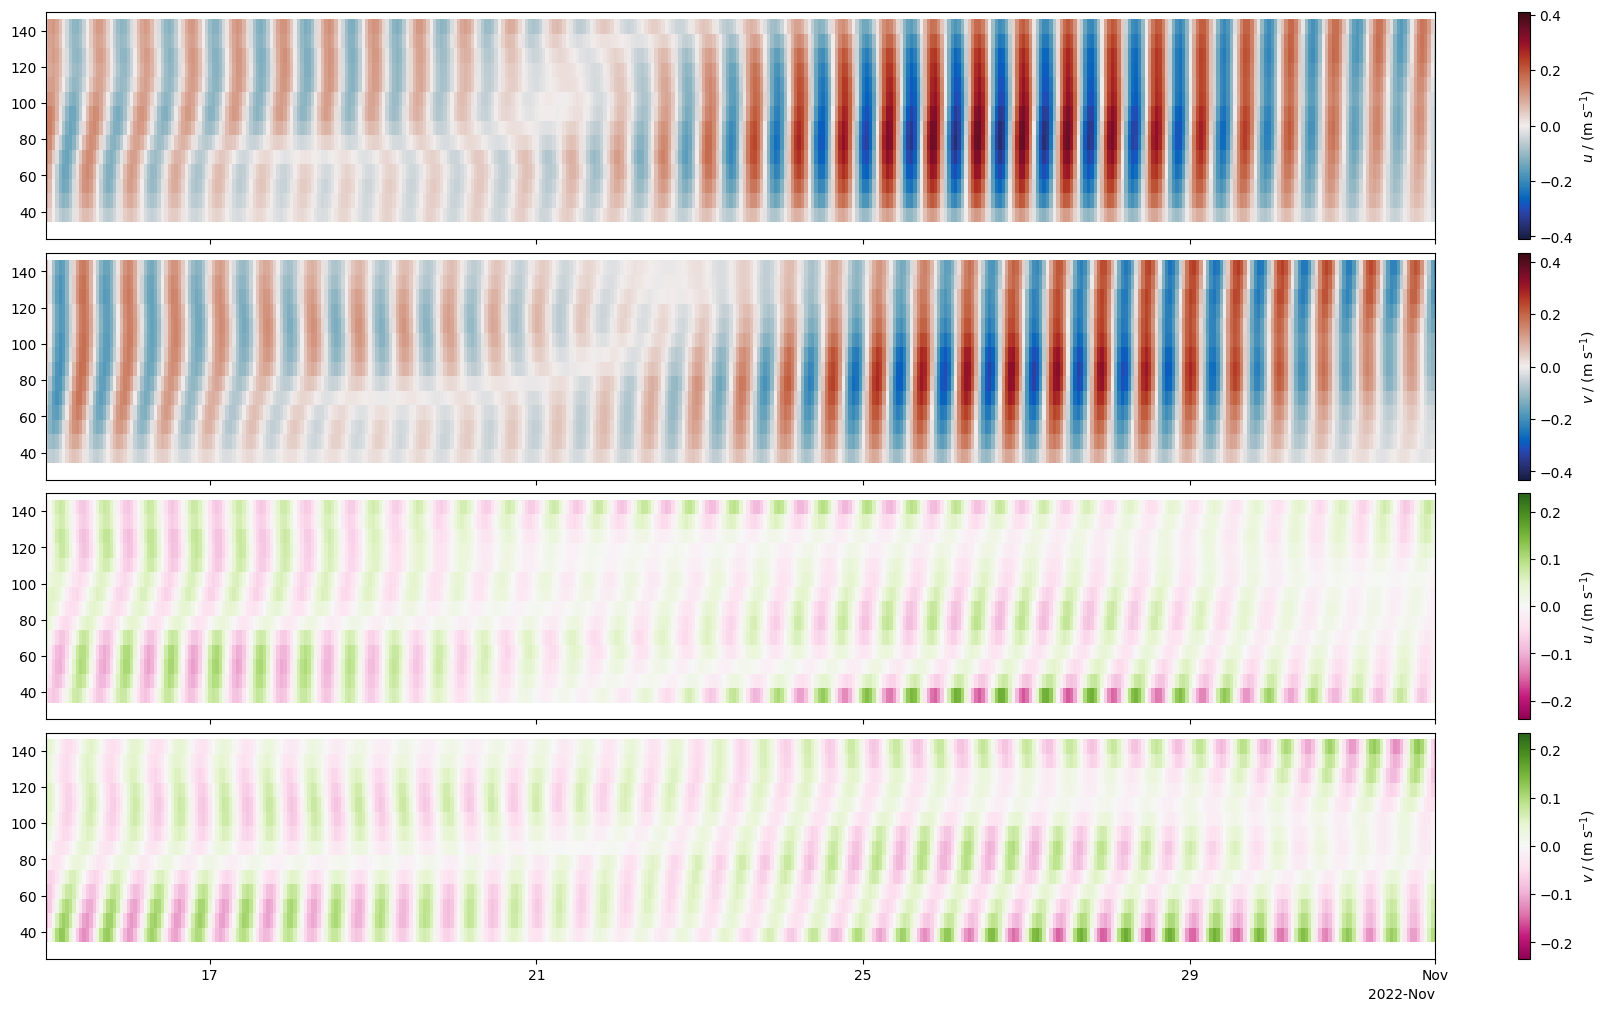

In [29]:
fig, ax = plt.subplots(nrows=4, sharex=True, sharey=True, figsize=(16, 10), layout="constrained")

im0 = ax[0].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im2 = ax[2].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.sub(u_f.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap="PiYG",
)

im3 = ax[3].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.sub(v_f.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap="PiYG",
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

ubar = fig.colorbar(im2, ax=ax[2])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im3, ax=ax[3])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

# Filter to just tidal frequencies

In [12]:
def filter_to_semidiurnal(col):
    fs = 1 / (1 * 60 * 60)
    low_cut = 1 / (12.5 * 60 * 60)
    high_cut = 1 / (11.8 * 60 * 60)
    order = 40
    sos = signal.butter(N=order, Wn=(low_cut, high_cut), btype="bandpass", fs=fs, output="sos")
    filtered = signal.sosfiltfilt(sos, col.to_numpy())
    return pd.Series(filtered, index=col.index)


u_semi = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_semidiurnal, axis="index")
v_semi = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_semidiurnal, axis="index")

(0.01, 1.0)

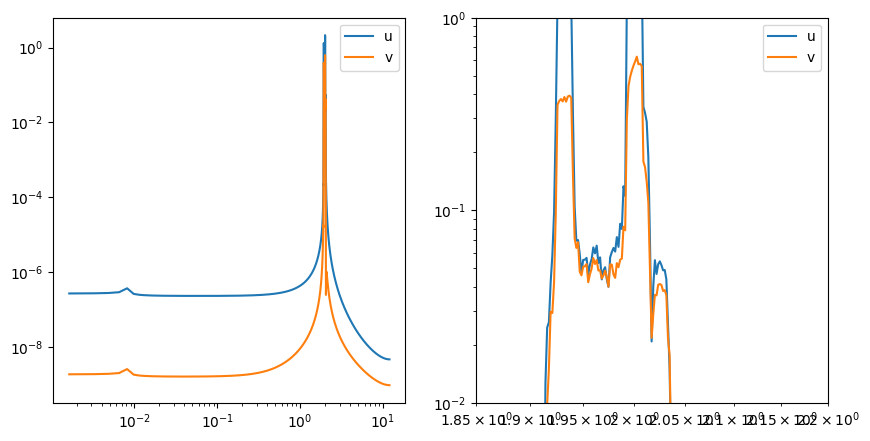

In [13]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 5

mab = 54.23
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_semi.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    v_semi.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
# ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(9e-4, 0.2)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.85, 2.2)
ax[1].set_ylim(1e-2, 1e0)

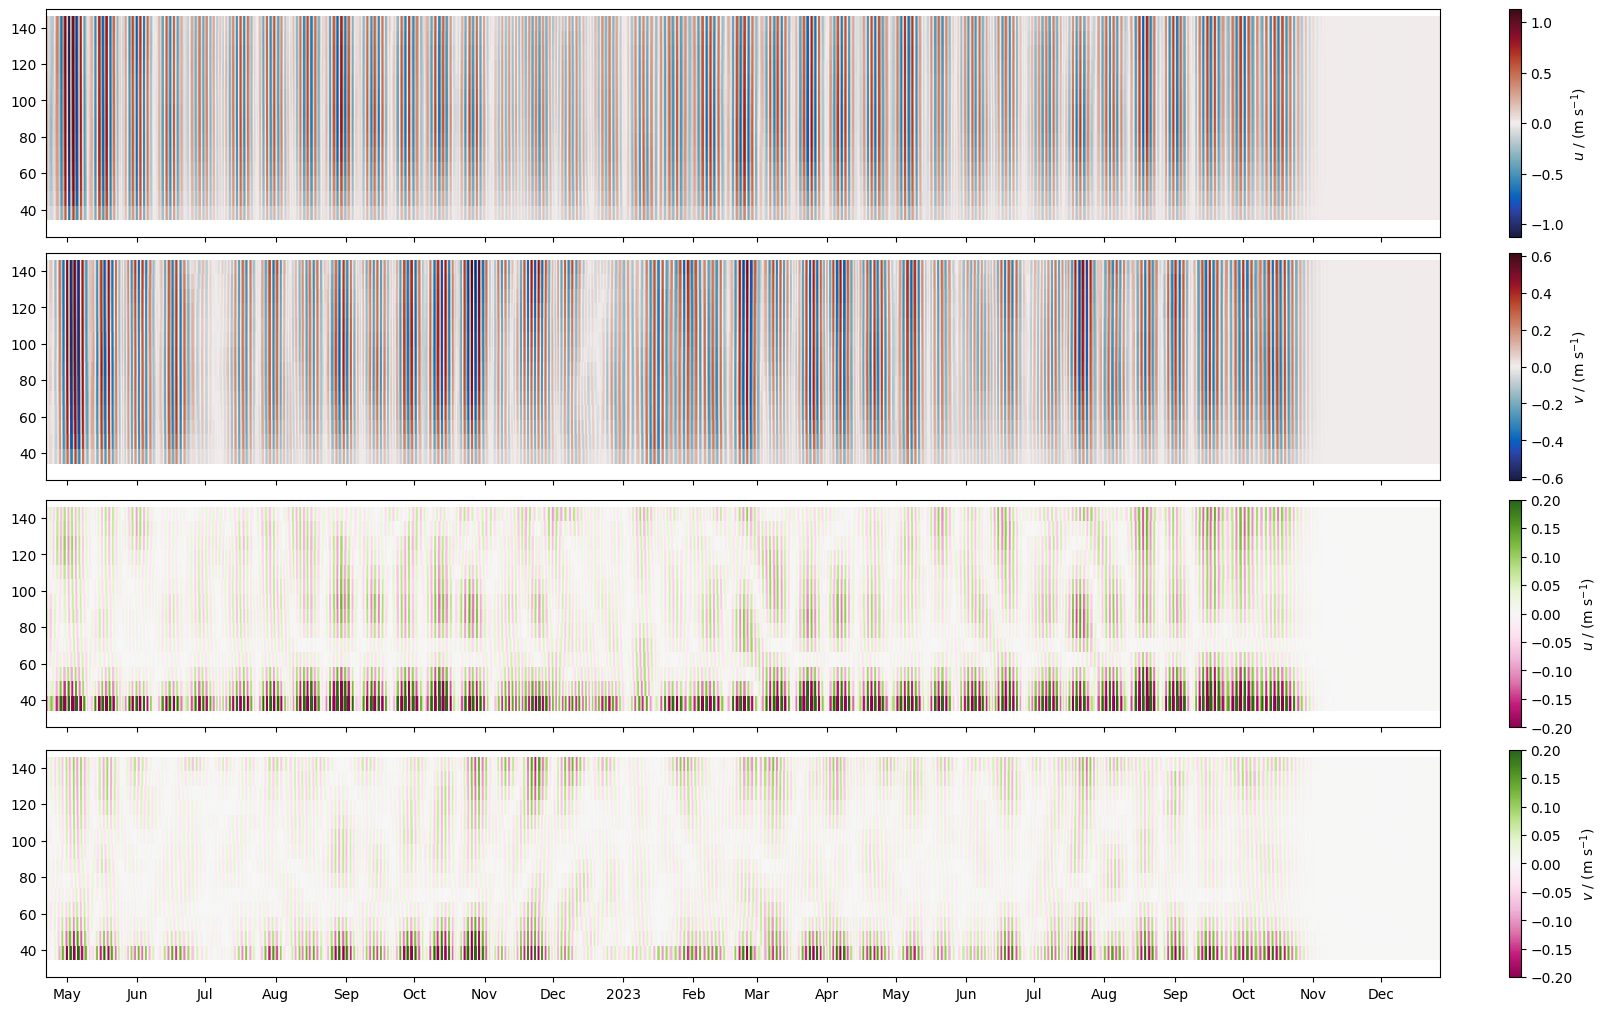

In [32]:
fig, ax = plt.subplots(nrows=4, sharex=True, sharey=True, figsize=(16, 10), layout="constrained")

im0 = ax[0].pcolormesh(
    u_semi.index,
    u_semi.columns,
    u_semi.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_semi.index,
    v_semi.columns,
    v_semi.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im2 = ax[2].pcolormesh(
    u_semi.index,
    u_semi.columns,
    u_semi.sub(u_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(halfrange=0.2),
    cmap="PiYG",
)

im3 = ax[3].pcolormesh(
    v_semi.index,
    v_semi.columns,
    v_semi.sub(v_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(halfrange=0.2),
    cmap="PiYG",
)
ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

ubar = fig.colorbar(im2, ax=ax[2])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im3, ax=ax[3])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=32)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

In [ ]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, figsize=(16, 5), layout="constrained")

MAX_REASONABLE_VELOCITY = 4
max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    u_semi.index,
    u_semi.columns,
    (u_semi - u_semi.mean(axis="columns")).to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_semi.index,
    v_semi.columns,
    (v_semi - v_semi.mean(axis="columns")).to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

# 2D Spectral Analysis

In [38]:
def filter_to_fN(col):
    fs = 1 / (1 * 60 * 60)
    cut = 1 / (13.8 * 60 * 60)
    order = 40
    sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
    filtered = signal.sosfiltfilt(sos, col.to_numpy())
    return pd.Series(filtered, index=col.index)


u_fN = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_fN, axis="index")
v_fN = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_fN, axis="index")

(0.01, 1.0)

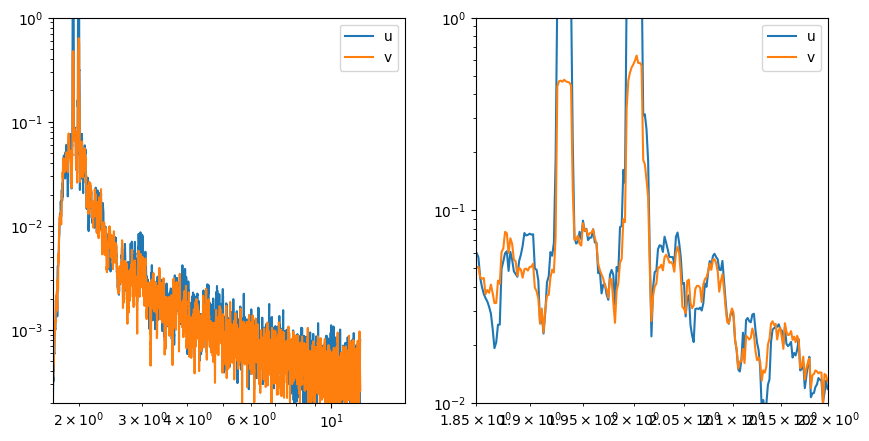

In [43]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 5

mab = 54.23
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_fN.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    v_fN.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
ax[0].set_xlim(1.7, 16)
ax[0].set_ylim(2e-4, 1)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.85, 2.2)
ax[1].set_ylim(1e-2, 1e0)

In [45]:
u_fN.shape

(14731, 21)

In [47]:
def decompose_CV_up_dn(CV):
    """
    COPYRIGHT: SIMON REIFENBERG
    For a two-dimensional velocity field CV (time x depth), this function returns
    a decomposed velocity field based on 2D-fft filtering.

    Input must have dimensions N_TIME x N_DEPTH.

    The convention for the returned quadrant in terms of energy propagation is
    consistent with z decreasing with depth, with z=0 at the ocean surface.

    HOWEVER, this means that for an array where CV[:,0] is the bin closest to
    the surface and the associated depth array is positive-increasing, i.e.
    D[1] > D[0], the FFT returns the quadrants as for "physical z"
    DECREASING with depth. This is related to the array indexing.

    I am quite confused.

    Here is a scriptlet for simple sanity checks: <to be copied here>
    """

    NT, NZ = CV.shape

    F = np.fft.fftshift(np.fft.fft2(CV))

    freq = np.fft.fftshift(np.fft.fftfreq(NT))
    mm = np.fft.fftshift(np.fft.fftfreq(NZ))

    FREQ, MM = np.meshgrid(freq, mm, indexing="ij")

    Q1_pp = (FREQ > 0) & (MM > 0)  # downward
    Q2_pn = (FREQ > 0) & (MM < 0)  # upward
    Q3_nn = (FREQ < 0) & (MM < 0)  # downward
    Q4_np = (FREQ < 0) & (MM > 0)  # upward

    cv_1 = np.fft.ifft2(np.fft.ifftshift(Q1_pp * F))
    cv_2 = np.fft.ifft2(np.fft.ifftshift(Q2_pn * F))
    cv_3 = np.fft.ifft2(np.fft.ifftshift(Q3_nn * F))
    cv_4 = np.fft.ifft2(np.fft.ifftshift(Q4_np * F))

    return {
        "E_dn_CCW": cv_1,
        "E_up_CCW": cv_2,
        "E_dn_CW": cv_3,
        "E_up_CW": cv_4,
    }

In [79]:
results = decompose_CV_up_dn(
    u_f.dropna(axis="columns", how="all") + 1j * v_f.dropna(axis="columns", how="all")
)

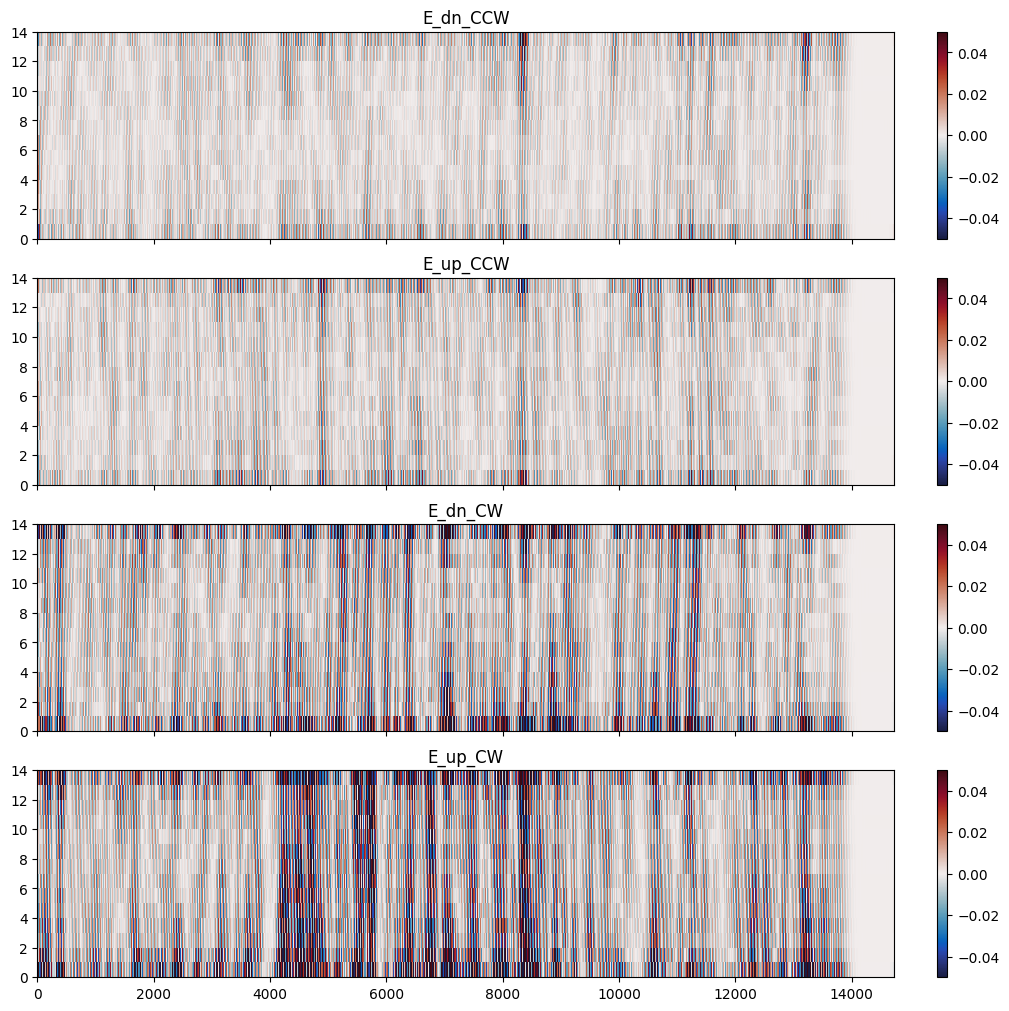

In [83]:
fig, ax = plt.subplots(nrows=4, sharex=True, sharey=True, layout="constrained", figsize=(10, 10))
for i, (name, data) in enumerate(results.items()):
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        np.real(data).T, norm=mcolors.CenteredNorm(halfrange=0.05), cmap=cm.cm.balance
    )
    fig.colorbar(im, ax=ax[i])

# Comparison with Energy and Wind

### horizontal kinetic energy

In [ ]:
u_series = u[94.23][30:]
v_series = v[94.23][30:]
assert not np.any(u_series.isna())
assert not np.any(v_series.isna())

In [ ]:
fs = 1 / (1 * 60 * 60)  # sampling period of 1 hour
cut = 1 / (13.8 * 60 * 60)  # tail end of the continuum
# cut = 1 / (7 * 60 * 60)  # tail end of the continuum
order = 40

sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
# use filtfilt with 2 filtering passes to prevent an artificial phase shift
superinertial_u = pd.Series(index=u_series.index, data=signal.sosfiltfilt(sos, u_series.values))
superinertial_v = pd.Series(index=v_series.index, data=signal.sosfiltfilt(sos, v_series.values))

In [ ]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_series.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
freq, velocity_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    superinertial_u.values, dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
plt.loglog(freq, velocity_spectrum)
plt.gca().set_xlim(0.6, 16)
plt.gca().set_ylim(8e-4, 3)

In [ ]:
hke = 1 / 2 * (superinertial_u + 1j * superinertial_v).abs() ** 2
hke.plot()
smooth_hke = hke.rolling(window="5D", center=True).mean()
smooth_hke.plot()

In [ ]:
hke

### Inertial Wind

In [ ]:
inertial_wind = pd.read_csv(INTERIM_DATA_DIR / "inertial_wind_2022_2023.csv")
inertial_wind = inertial_wind.set_index(pd.to_datetime(inertial_wind["Unnamed: 0"]))
inertial_wind = inertial_wind.drop("Unnamed: 0", axis="columns")
for _i, col in enumerate(inertial_wind.columns):
    inertial_wind[col] = inertial_wind[col].str.replace("i", "j").apply(lambda x: complex(x))
inertial_wind_at_C = inertial_wind["C"]
inertial_wind_at_C = inertial_wind_at_C.loc[: hke.index[-1]]

In [ ]:
smooth_wind = pd.Series(
    index=inertial_wind_at_C.index, data=smooth(inertial_wind_at_C.abs().to_numpy(), 30)
)

In [ ]:
fig, ax = plt.subplots(1, figsize=(8, 2), layout="constrained")

ax.set_ylabel("hke")  # \n$\\varepsilon_{\\mathrm{IGW}}\\,$(W$\\,$kg$^{-1}$)")

locator = mdates.AutoDateLocator(minticks=8, maxticks=12)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

(l_hke,) = ax.plot(
    smooth_hke.index,
    smooth_hke.to_numpy(),
    label="hke",  # $\\varepsilon_\\text{IGW}(t)$",
    lw=2,
)

ax2 = ax.twinx()
ax2.set_zorder(-1)
ax.set_facecolor("None")
(l_wind,) = ax2.plot(
    smooth_wind.index,
    smooth_wind.values,
    color="tab:red",
    label="inertial wind",
    lw=2,
)

ax2.set_ylabel("inertial wind / (m/s)$")

ax.legend(
    handles=[l_hke, l_wind],
    # title="measured at mooring C, 2350$\\,$m depth, 143$\\,$mab",
    ncol=1,
    fontsize=6,
    framealpha=0.9,
)

In [ ]:
#